# CartPole-v1: Q-learning y Stochastic Q-learning

Este notebook resume los experimentos. El entrenamiento está en `cartpole_rl/` y
las corridas completas se reproducen con:

```bash
python -m experiments.run_experiments --suite all   # ~1 h con 2 núcleos
python make_figures.py
```

Acá solo se cargan los resultados guardados en `results/` y un modelo de `models/`.

In [1]:
import json, pickle, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from cartpole_rl import evaluate, make_discretizer, make_env

def table(suite, extra=()):
    groups = json.loads((ROOT / "results" / f"{suite}.json").read_text())["groups"]
    cols = ["eval_exact_mean", "eval_exact_std_between_seeds", "success_rate_mean",
            "train_mean_last_1000", "train_seconds_mean", *extra]
    return pd.DataFrame(groups).T[cols]

## 1. Discretización del estado

| | Bins (pos, vel, ángulo, vel. angular) | Estados | Tipo |
|---|---|---|---|
| D1 | 10 × 10 × 20 × 20 | 40.000 | uniforme |
| D2 | 8 × 8 × 25 × 25 | 40.000 | uniforme, más resolución en el poste |
| D3 | 6 × 6 × 12 × 12 | 5.184 | no uniforme: intervalos finos cerca del equilibrio |

Las acciones de CartPole-v1 ya son discretas (2). La discretización de acciones
se usa en la sección 3.

In [2]:
for name in ("D1", "D2", "D3"):
    print(make_discretizer(name).describe())
table("discretization")

D1 uniforme (10x10x20x20 = 40000 estados)
D2 énfasis en el poste (8x8x25x25 = 40000 estados)
D3 no uniforme compacta (6x6x12x12 = 5184 estados)


,eval_exact_mean,eval_exact_std_between_seeds,success_rate_mean,train_mean_last_1000,train_seconds_mean
D1,500.0,0.0,1.0,490.09,266.0
D2,464.61,26.58,0.79,450.38,325.1
D3,158.31,18.7,0.0,157.1,117.1


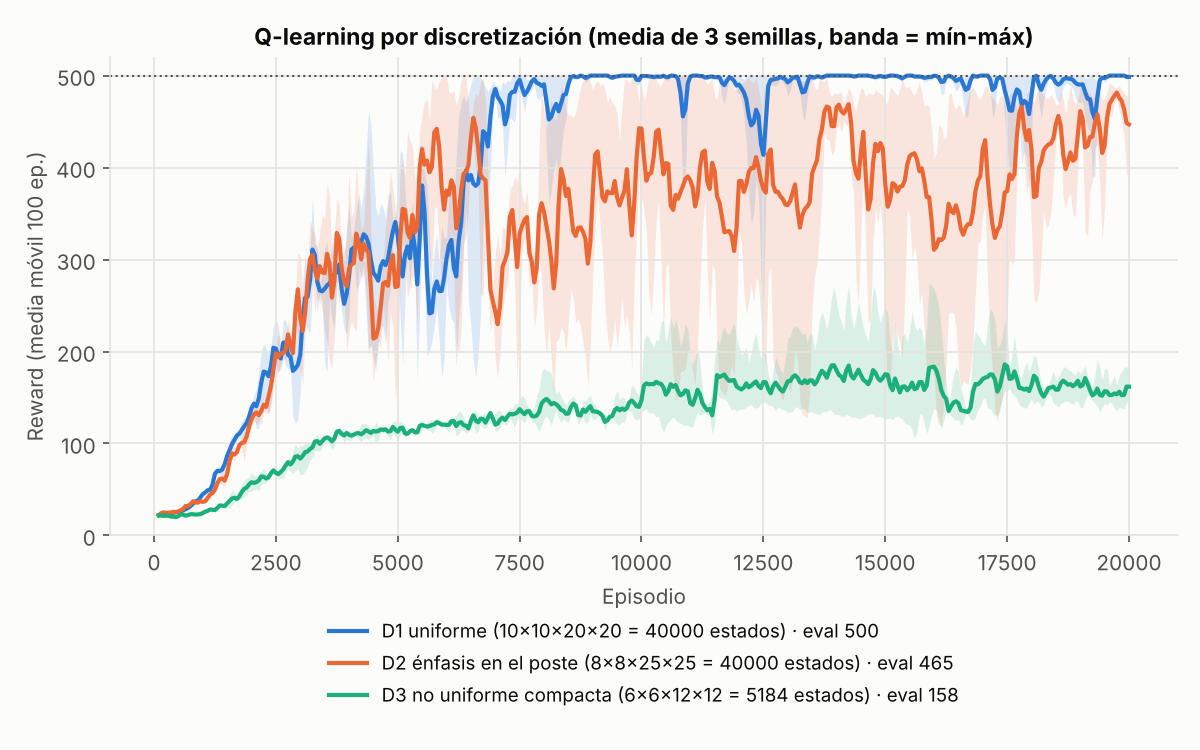

In [3]:
display(Image(ROOT / "figures" / "discretizacion_curvas.png"))

## 2. Hiperparámetros

Se varía un parámetro por vez respecto de la configuración base (alpha=0.2, gamma=0.9995, decay de epsilon=0.9995), con 10.000 episodios y 3 semillas.

,eval_exact_mean,eval_exact_std_between_seeds,success_rate_mean,train_mean_last_1000,train_seconds_mean
base,500.0,0.0,1.0,499.17,151.6
alpha=0.05,357.72,131.1,0.41,339.94,85.9
alpha=0.1,484.96,18.5,0.91,383.81,137.5
alpha=0.4,500.0,0.0,1.0,494.58,144.2
gamma=0.99,330.15,120.1,0.347,382.67,125.8
gamma=0.999,456.57,60.4,0.77,475.77,138.9
decay=0.999,354.2,108.79,0.44,433.92,158.2
decay=0.9998,461.97,47.63,0.757,370.68,57.7


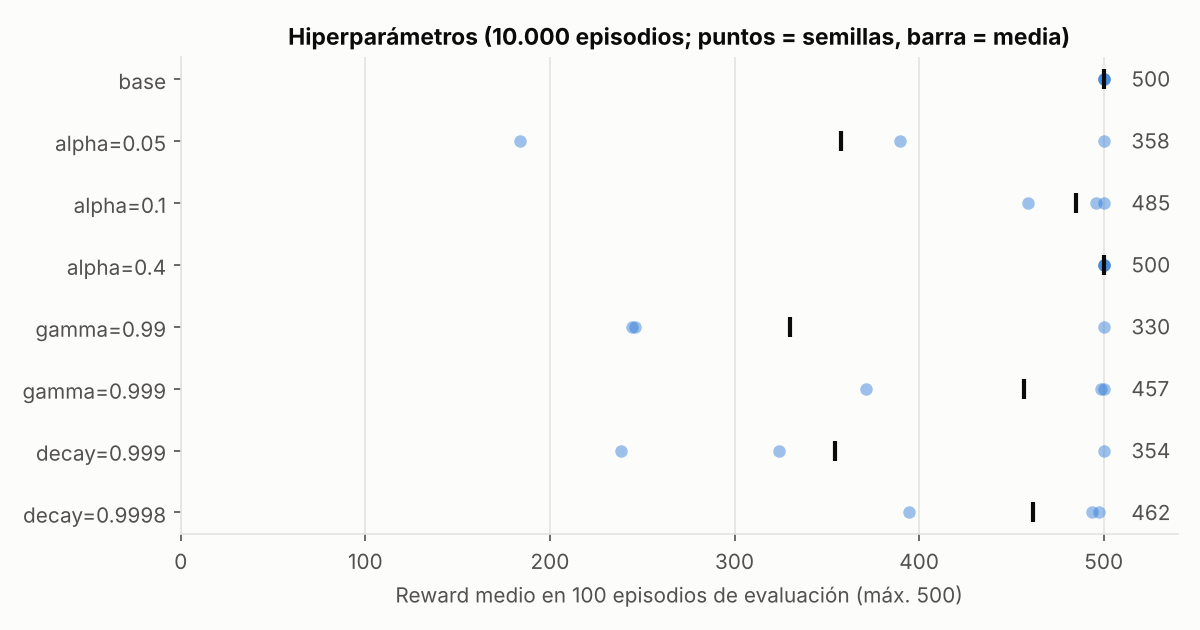

In [4]:
display(table("hyperparams")); display(Image(ROOT / "figures" / "hiperparametros.png"))

## 3. Stochastic Q-learning

La fuerza se discretiza en `n` niveles en [-10, 10] N. Stochastic Q-learning
reemplaza `max`/`argmax` por `stoch max`/`stoch argmax` sobre ⌈ln n⌉ acciones al
azar más las 2 últimas acciones explotadas en el estado.
`Q/paso` cuenta cuántos valores Q se consultan por paso de entrenamiento.

,eval_exact_mean,eval_exact_std_between_seeds,success_rate_mean,train_mean_last_1000,train_seconds_mean,q_evals_per_step_mean,us_per_step_mean,eval_stochastic_mean,stoch_max_exact_ratio_mean
q n=11,500.0,0.0,1.0,499.29,158.9,21.368,25.37,NaN,NaN
stochq n=11,390.34,153.98,0.663,449.09,275.2,8.636,46.52,391.28,0.9897
q n=51,495.6,6.22,0.983,496.44,141.4,99.82,26.28,NaN,NaN
stochq n=51,492.82,7.09,0.98,490.03,238.9,11.238,49.06,492.97,0.9902


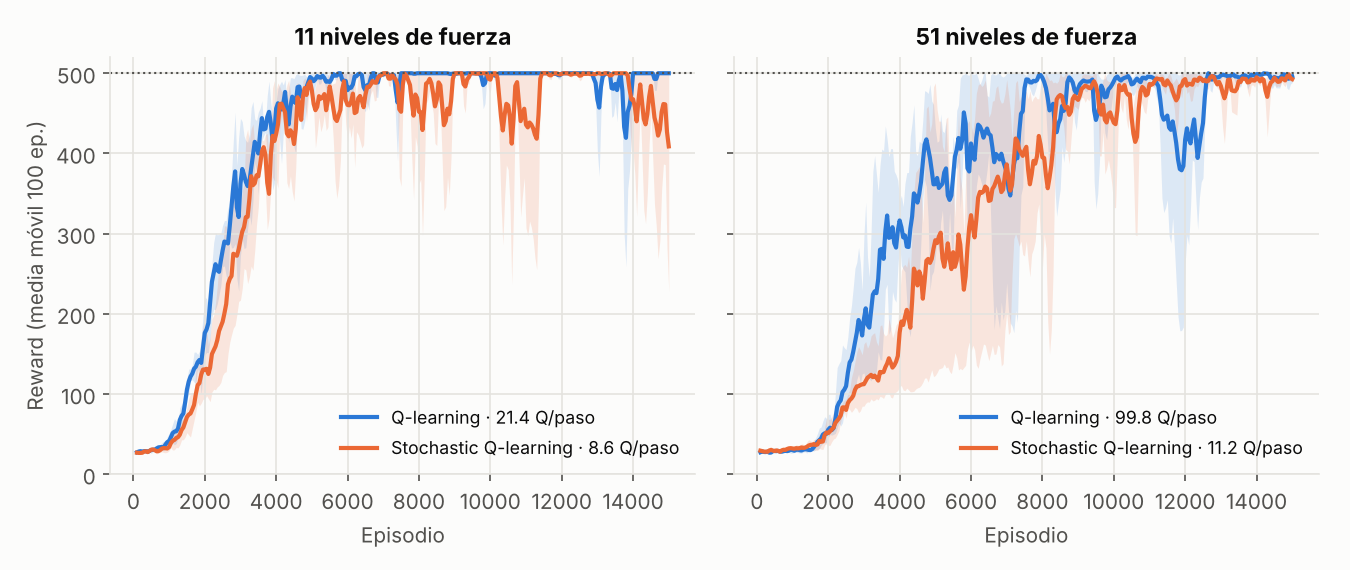

In [5]:
display(table("actions", extra=["q_evals_per_step_mean", "us_per_step_mean", "eval_stochastic_mean",
                                 "stoch_max_exact_ratio_mean"]))
display(Image(ROOT / "figures" / "stochastic_vs_q.png"))

## 4. Cargar y evaluar un modelo guardado

In [6]:
with open(ROOT / "models" / "disc_D1_s0.pkl", "rb") as f:
    model = pickle.load(f)
disc = make_discretizer(model["discretization"])
env = make_env(model["n_actions"])
stats = evaluate(env, model["Q"], disc, episodes=100)
print(disc.describe(), "| reward medio:", stats["mean"], "| episodios completos:", f"{stats['success_rate']:.0%}")

D1 uniforme (10x10x20x20 = 40000 estados) | reward medio: 500.0 | episodios completos: 100%
